In [ ]:
%pip install -U opencv-python pandas numpy matplotlib pillow
%pip install -U ultralytics

In [ ]:
import os
import cv2
import json
import shutil
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# RetailMind project directories
PROJECT_DIR = Path("RetailMind")
DATA_DIR = PROJECT_DIR / "data"
RAW_DIR = DATA_DIR / "raw"
IMAGE_DIR = RAW_DIR / "images"
ANNOTATION_DIR = DATA_DIR / "annotations"

for directory in [PROJECT_DIR, DATA_DIR, RAW_DIR,
                  IMAGE_DIR, ANNOTATION_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("RetailMind directories created.")
print("Project location:", PROJECT_DIR.resolve())

In [ ]:
# Update this path if your extracted dataset is elsewhere.
DATASET_ROOT = RAW_DIR

CSV_PATH = DATASET_ROOT / "styles.csv"

assert CSV_PATH.exists(), (
    f"styles.csv not found at {CSV_PATH}. "
    "Download and extract the Kaggle dataset first."
)

df = pd.read_csv(CSV_PATH, on_bad_lines="skip")

print("Dataset shape:", df.shape)
print("\nAvailable columns:")
print(df.columns.tolist())

df.head()

In [ ]:
# Validate required columns
required_columns = ["id", "articleType"]

for column in required_columns:
    assert column in df.columns, f"Missing column: {column}"

# Construct image paths
df["image_path"] = df["id"].astype(str).apply(
    lambda x: str(IMAGE_DIR / f"{x}.jpg")
)

# Keep records with valid labels and existing images
df = df[
    df["articleType"].notna() &
    df["image_path"].apply(os.path.exists)
].copy()

df.reset_index(drop=True, inplace=True)

print("Available images:", len(df))
print("\nProduct category distribution:")

display(
    df["articleType"]
    .value_counts()
    .head(20)
    .to_frame("image_count")
)

In [ ]:
# Select random images
sample_df = df.sample(
    n=min(12, len(df)),
    random_state=SEED
)

plt.figure(figsize=(14, 10))

for index, (_, row) in enumerate(sample_df.iterrows()):

    image = cv2.imread(row["image_path"])

    if image is None:
        continue

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.subplot(3, 4, index + 1)
    plt.imshow(image)
    plt.title(row["articleType"])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
SELECTED_CATEGORIES = [
    "Shirts",
    "Trousers",
    "Dresses",
    "Shoes",
    "Handbags"
]

retail_df = df[
    df["articleType"].isin(SELECTED_CATEGORIES)
].copy()

print("Selected images:", len(retail_df))

print("\nImages per category:")
print(retail_df["articleType"].value_counts())

In [ ]:
# Select 25 images for annotation

sample_df = (
    retail_df.groupby("articleType", group_keys=False)
    .head(5)
)

sample_df[["id", "articleType", "image_path"]].to_csv(
    "retailmind_annotation_images.csv",
    index=False
)

print("Images selected:", len(sample_df))

In [ ]:
import tensorflow as tf
import tensorflow_hub as hub
import numpy as np
import cv2
import matplotlib.pyplot as plt
import time
import urllib.request

from ultralytics import YOLO

# 1. Download common test image
image_path = "bus.jpg"

urllib.request.urlretrieve(
    "https://ultralytics.com/images/bus.jpg",
    image_path
)

image = cv2.imread(image_path)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# 2. Load Faster R-CNN
faster_model = hub.load(
    "https://tfhub.dev/tensorflow/faster_rcnn/resnet50_v1_640x640/1"
)

# 3. Load SSD
ssd_model = hub.load(
    "https://tfhub.dev/tensorflow/ssd_mobilenet_v2/2"
)

# 4. Load YOLO
yolo_model = YOLO("yolo11n.pt")

# 5. Prepare TensorFlow input
input_tensor = tf.convert_to_tensor(
    image_rgb,
    dtype=tf.uint8
)[tf.newaxis, ...]

# 6. Run Faster R-CNN
start = time.perf_counter()
faster_output = faster_model(input_tensor)
faster_time = time.perf_counter() - start

# 7. Run SSD
start = time.perf_counter()
ssd_output = ssd_model(input_tensor)
ssd_time = time.perf_counter() - start

# 8. Run YOLO
start = time.perf_counter()
yolo_output = yolo_model.predict(
    image_path,
    conf=0.25,
    verbose=False
)
yolo_time = time.perf_counter() - start

print("Inference completed!")

print(f"Faster R-CNN: {faster_time:.3f} seconds")
print(f"SSD:          {ssd_time:.3f} seconds")
print(f"YOLO:         {yolo_time:.3f} seconds")

In [ ]:
# Extract and visualize predictions

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

# --------------------------------
# 1. Faster R-CNN
# --------------------------------
faster_image = image_rgb.copy()

f_boxes = faster_output["detection_boxes"][0].numpy()
f_scores = faster_output["detection_scores"][0].numpy()
f_classes = faster_output["detection_classes"][0].numpy()

h, w, _ = faster_image.shape

for box, score, cls in zip(f_boxes, f_scores, f_classes):

    if score < 0.5:
        continue

    ymin, xmin, ymax, xmax = box

    x1, y1 = int(xmin * w), int(ymin * h)
    x2, y2 = int(xmax * w), int(ymax * h)

    cv2.rectangle(faster_image, (x1, y1), (x2, y2), (255, 0, 0), 2)

    cv2.putText(
        faster_image,
        f"Class {int(cls)} {score:.2f}",
        (x1, max(y1 - 5, 15)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (255, 0, 0),
        2
    )

axes[0].imshow(faster_image)
axes[0].set_title(f"Faster R-CNN\n{faster_time:.2f}s")
axes[0].axis("off")


# --------------------------------
# 2. SSD
# --------------------------------
ssd_image = image_rgb.copy()

s_boxes = ssd_output["detection_boxes"][0].numpy()
s_scores = ssd_output["detection_scores"][0].numpy()
s_classes = ssd_output["detection_classes"][0].numpy()

for box, score, cls in zip(s_boxes, s_scores, s_classes):

    if score < 0.5:
        continue

    ymin, xmin, ymax, xmax = box

    x1, y1 = int(xmin * w), int(ymin * h)
    x2, y2 = int(xmax * w), int(ymax * h)

    cv2.rectangle(ssd_image, (x1, y1), (x2, y2), (0, 255, 0), 2)

    cv2.putText(
        ssd_image,
        f"Class {int(cls)} {score:.2f}",
        (x1, max(y1 - 5, 15)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (0, 255, 0),
        2
    )

axes[1].imshow(ssd_image)
axes[1].set_title(f"SSD\n{ssd_time:.2f}s")
axes[1].axis("off")


# --------------------------------
# 3. YOLO
# --------------------------------
yolo_image = yolo_output[0].plot()

axes[2].imshow(cv2.cvtColor(yolo_image, cv2.COLOR_BGR2RGB))
axes[2].set_title(f"YOLO11n\n{yolo_time:.2f}s")
axes[2].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Better visualization of Faster R-CNN and SSD

# COCO class names
COCO_CLASSES = [
    "background", "person", "bicycle", "car", "motorcycle",
    "airplane", "bus", "train", "truck", "boat",
    "traffic light", "fire hydrant", "stop sign", "parking meter",
    "bench", "bird", "cat", "dog", "horse", "sheep",
    "cow", "elephant", "bear", "zebra", "giraffe"
]

def draw_detections(image, boxes, scores, classes, title):

    output = image.copy()
    h, w, _ = output.shape

    count = 0

    for box, score, cls in zip(boxes, scores, classes):

        if score < 0.5:
            continue

        ymin, xmin, ymax, xmax = box

        x1, y1 = int(xmin * w), int(ymin * h)
        x2, y2 = int(xmax * w), int(ymax * h)

        class_id = int(cls)

        label = (
            COCO_CLASSES[class_id]
            if class_id < len(COCO_CLASSES)
            else f"Class {class_id}"
        )

        cv2.rectangle(
            output, (x1, y1), (x2, y2),
            (0, 255, 0), 3
        )

        cv2.putText(
            output,
            f"{label}: {score:.2f}",
            (x1, max(y1 - 8, 20)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (255, 0, 0),
            2
        )

        count += 1

    plt.figure(figsize=(10, 7))
    plt.imshow(output)
    plt.title(f"{title} | Detections: {count}")
    plt.axis("off")
    plt.show()


# Faster R-CNN
draw_detections(
    image_rgb,
    f_boxes,
    f_scores,
    f_classes,
    "Faster R-CNN"
)

# SSD
draw_detections(
    image_rgb,
    s_boxes,
    s_scores,
    s_classes,
    "SSD"
)

In [13]:
import os
import pandas as pd

DATASET_PATH = r"E:\LTM\Batch-3\DL\RetailMind\data\raw"

IMAGE_DIR = os.path.join(DATASET_PATH, "images")
CSV_PATH = os.path.join(DATASET_PATH, "styles.csv")

df = pd.read_csv(CSV_PATH, on_bad_lines="skip")

df["image_path"] = df["id"].apply(
    lambda x: os.path.join(IMAGE_DIR, f"{x}.jpg")
)

retail_df = df[df["image_path"].apply(os.path.exists)].copy()

print("Total metadata records:", len(df))
print("Images available:", len(retail_df))

display(retail_df[["id", "articleType", "image_path"]].head())

Total metadata records: 44424
Images available: 44419


,id,articleType,image_path
0,15970,Shirts,E:\LTM\Batch-3\DL\RetailMind\data\raw\images\1...
1,39386,Jeans,E:\LTM\Batch-3\DL\RetailMind\data\raw\images\3...
2,59263,Watches,E:\LTM\Batch-3\DL\RetailMind\data\raw\images\5...
3,21379,Track Pants,E:\LTM\Batch-3\DL\RetailMind\data\raw\images\2...
4,53759,Tshirts,E:\LTM\Batch-3\DL\RetailMind\data\raw\images\5...


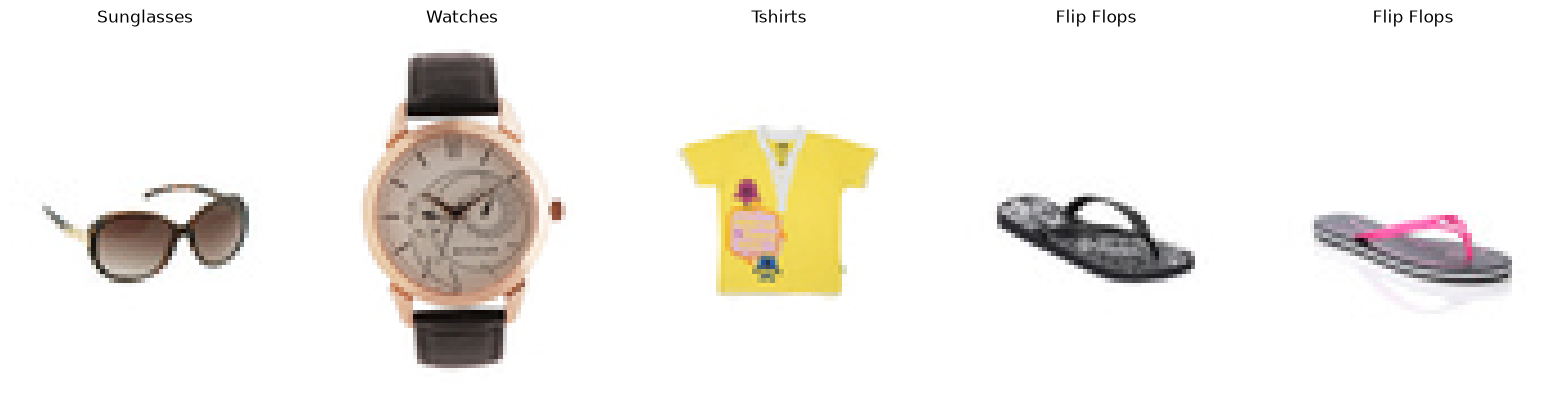

In [14]:
import matplotlib.pyplot as plt
import cv2

sample_images = retail_df.sample(5, random_state=42)

fig, axes = plt.subplots(1, 5, figsize=(16, 4))

for ax, (_, row) in zip(axes, sample_images.iterrows()):
    image = cv2.imread(row["image_path"])
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    ax.imshow(image)
    ax.set_title(row["articleType"])
    ax.axis("off")

plt.tight_layout()
plt.show()

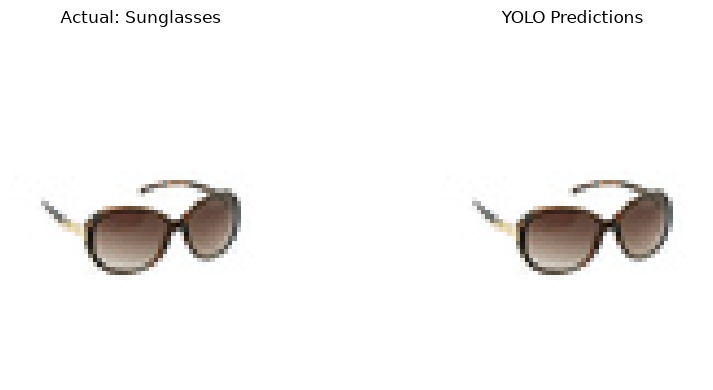

Product category: Sunglasses
YOLO detections:
No objects detected.
--------------------------------------------------


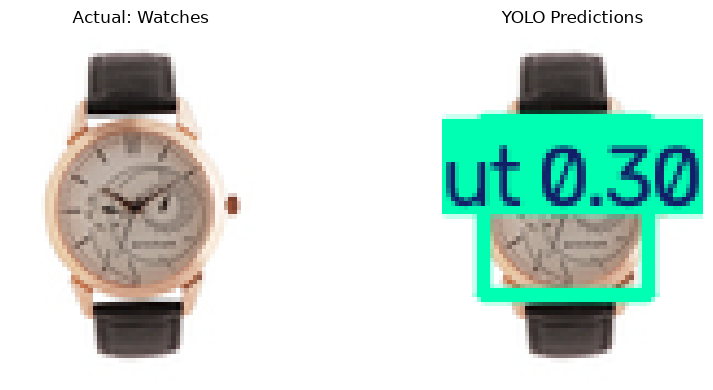

Product category: Watches
YOLO detections:
donut 0.304
--------------------------------------------------


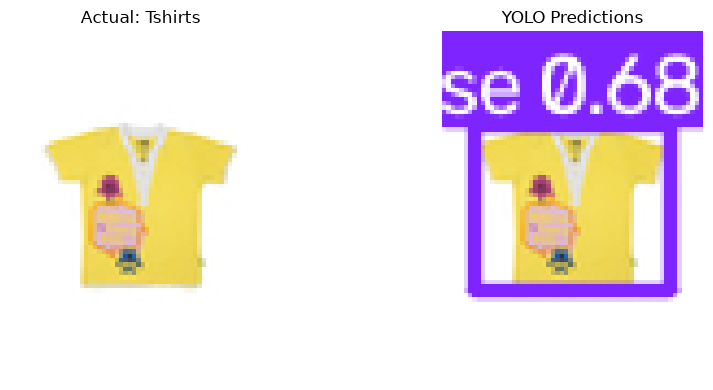

Product category: Tshirts
YOLO detections:
vase 0.682
--------------------------------------------------


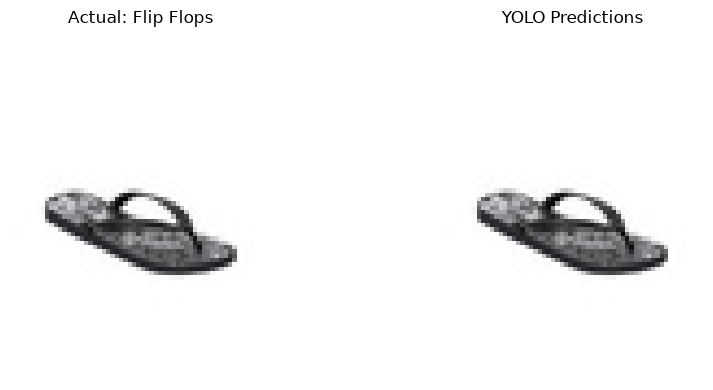

Product category: Flip Flops
YOLO detections:
No objects detected.
--------------------------------------------------


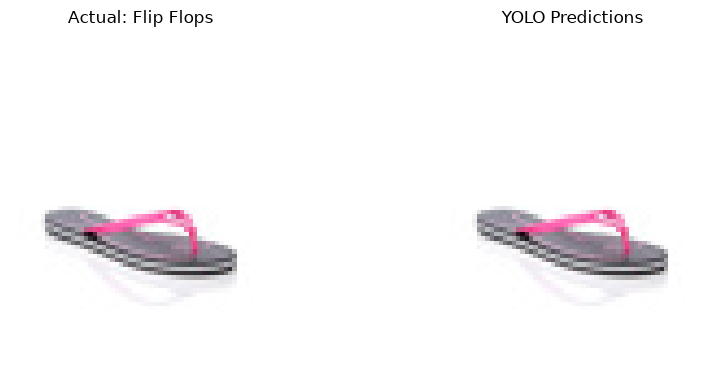

Product category: Flip Flops
YOLO detections:
No objects detected.
--------------------------------------------------


In [15]:
sample_images = retail_df.sample(5, random_state=42)

for _, row in sample_images.iterrows():

    image_path = row["image_path"]

    # Run object detection
    results = yolo_model.predict(
        source=image_path,
        conf=0.25,
        verbose=False
    )

    result = results[0]

    # Original image
    original = cv2.imread(image_path)
    original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

    # YOLO annotated image
    detected = cv2.cvtColor(
        result.plot(), cv2.COLOR_BGR2RGB
    )

    # Display side by side
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    axes[0].imshow(original)
    axes[0].set_title(f"Actual: {row['articleType']}")
    axes[0].axis("off")

    axes[1].imshow(detected)
    axes[1].set_title("YOLO Predictions")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

    print("Product category:", row["articleType"])
    print("YOLO detections:")

    if result.boxes is not None and len(result.boxes) > 0:
        for box in result.boxes:
            class_id = int(box.cls.item())
            confidence = float(box.conf.item())

            print(
                yolo_model.names[class_id],
                round(confidence, 3)
            )
    else:
        print("No objects detected.")

    print("-" * 50)

# 1. What is image segmentation?

In object detection, we draw a rectangular bounding box around an object.

But imagine a photograph of a person wearing a shirt. The bounding box includes not only the shirt but also some background pixels.

Image segmentation goes one step further: it identifies the exact pixels that belong to an object.

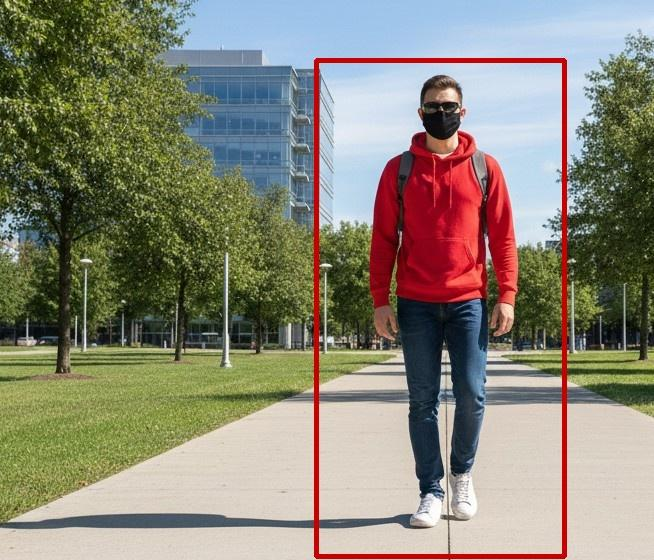

Object detection

Identifies the object using a rectangular bounding box.

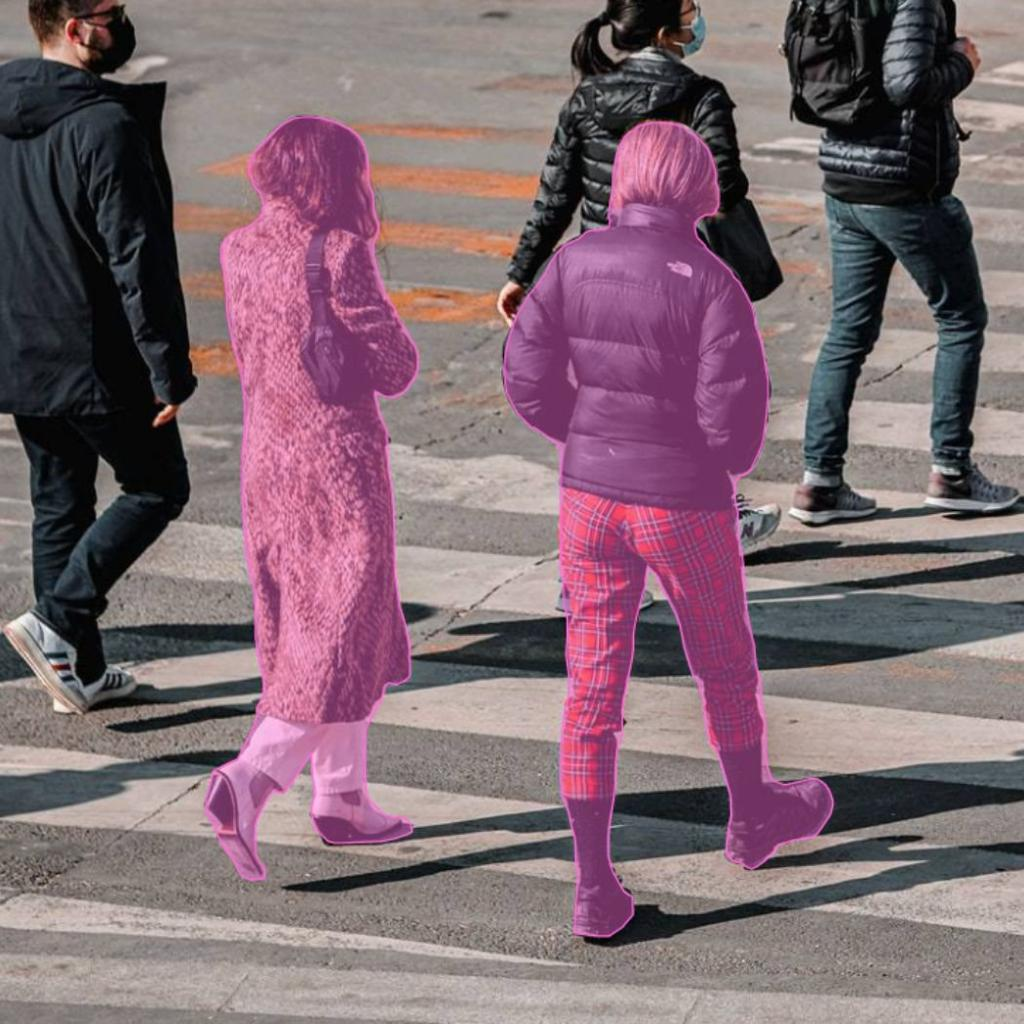

Image segmentation

Identifies the actual pixels belonging to the object.

Think of it this way:

- Classification: What is in this image?
- Object detection: What is present and where?
- Segmentation: Which exact pixels belong to each object?

# 2. Three types of image segmentation

This is the most important conceptual distinction.

## A. Semantic segmentation

Every pixel is assigned a class label.

For example, in a street photograph:

- All road pixels → Road
- All car pixels → Car
- All person pixels → Person
- All building pixels → Building

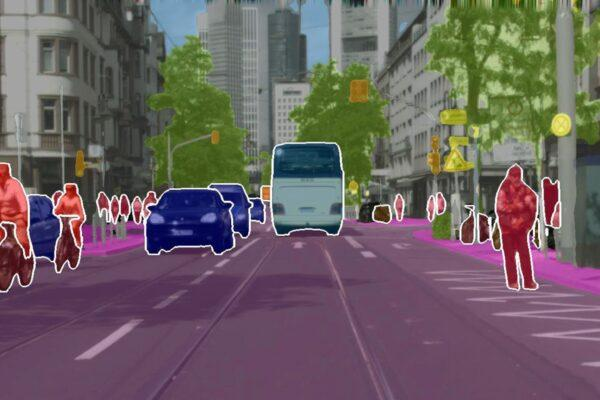

Notice something important: if there are five cars, semantic segmentation labels all five as the same class. It doesn't distinguish car 1 from car 2.

## B. Instance segmentation

Here, the model identifies individual object instances separately.

For example:

- Car 1 → Mask 1
- Car 2 → Mask 2
- Car 3 → Mask 3

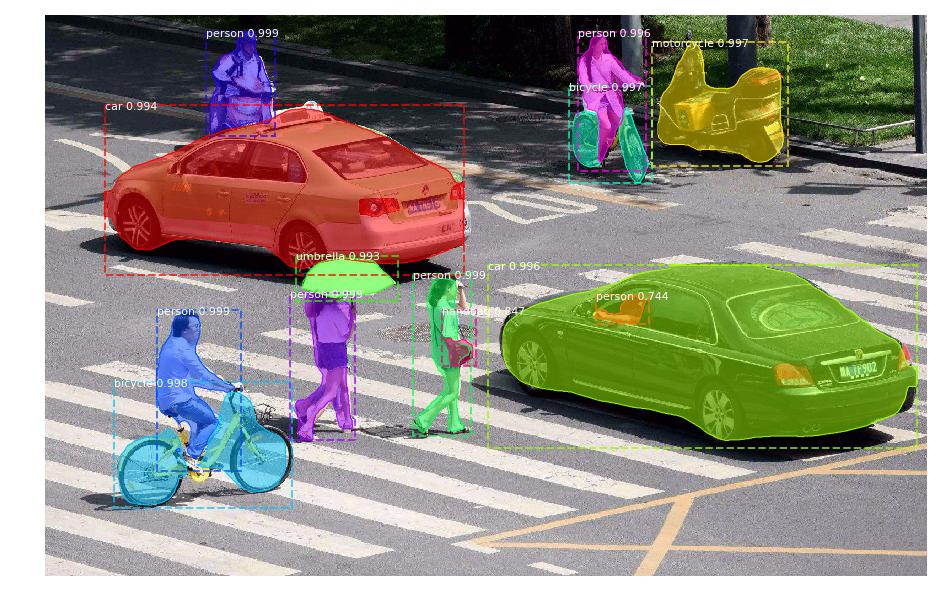

This is useful when we need to count individual objects or separate overlapping objects.

## C. Panoptic segmentation

This combines semantic and instance segmentation.

- Countable objects such as cars and people are individually identified.
- Background or surrounding regions such as road, sky and buildings are assigned semantic labels.

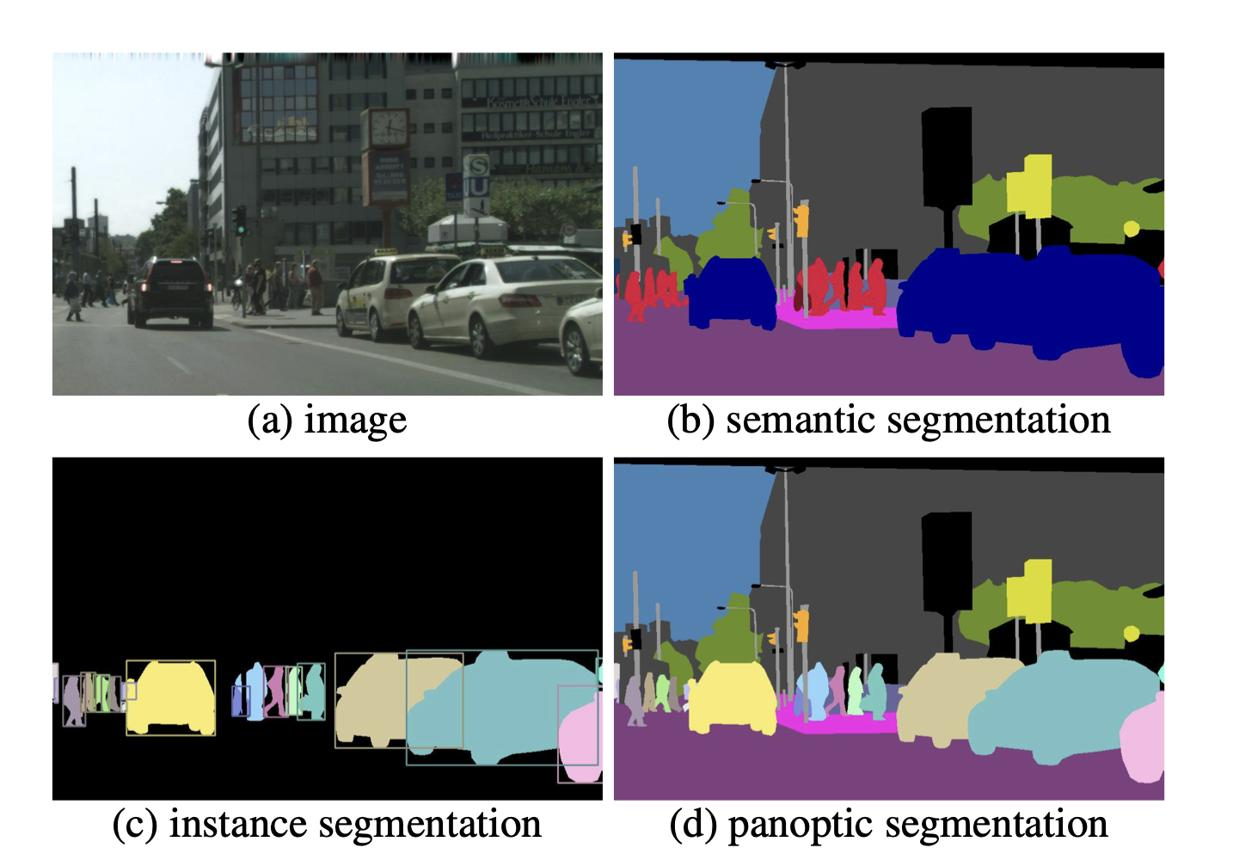

# 3. How does segmentation connect to RetailMind?

Let's use our fashion catalog example.

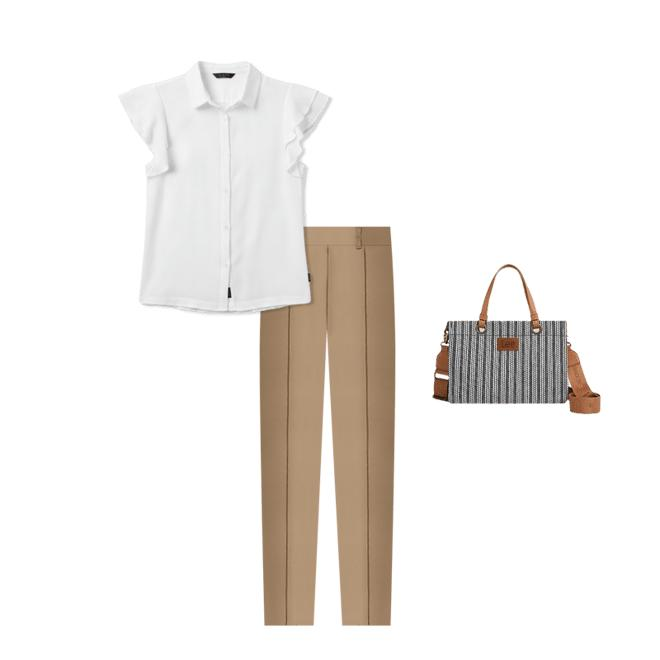

Suppose RetailMind receives an image of a model wearing a shirt and trousers.

| Requirement                                 | Suitable approach                 |
| ------------------------------------------- | --------------------------------- |
| Identify whether the image contains a shirt | Classification                    |
| Locate the shirt with a bounding box        | Object detection                  |
| Extract the exact shirt region              | Instance segmentation             |
| Remove the background                       | Segmentation / background matting |

In [ ]:
from ultralytics import YOLO

# Load pretrained YOLO segmentation model
seg_model = YOLO("yolo11n-seg.pt")

In [ ]:
import matplotlib.pyplot as plt
import cv2

# Select one catalog image
sample = retail_df.sample(1, random_state=42).iloc[0]

image_path = sample["image_path"]

# Run segmentation
results = seg_model.predict(
    source=image_path,
    conf=0.25,
    verbose=False
)

result = results[0]

# Read original image
original = cv2.imread(image_path)
original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

# Generate annotated image with segmentation masks
segmented = cv2.cvtColor(
    result.plot(),
    cv2.COLOR_BGR2RGB
)

# Display both images
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(original)
axes[0].set_title(f"Original: {sample['articleType']}")
axes[0].axis("off")

axes[1].imshow(segmented)
axes[1].set_title("YOLO Instance Segmentation")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Check whether segmentation masks were generated
if result.masks is not None:

    masks = result.masks.data.cpu().numpy()

    print("Number of object masks:", len(masks))
    print("Mask dimensions:", masks.shape)

    # Display the first object's actual mask
    plt.figure(figsize=(6, 5))
    plt.imshow(masks[0], cmap="gray")
    plt.title("Actual Segmentation Mask")
    plt.axis("off")
    plt.show()

else:
    print("No segmentation masks generated.")

In [ ]:
print("Model type:", seg_model.task)
print("Model weights:", seg_model.ckpt_path)

print("Detection boxes:", result.boxes is not None)
print("Segmentation masks:", result.masks is not None)

In [ ]:
results = seg_model.predict(
    source="https://ultralytics.com/images/bus.jpg",
    conf=0.25,
    verbose=False
)

test_result = results[0]

print("Boxes:", len(test_result.boxes))
print(
    "Masks:",
    None if test_result.masks is None
    else test_result.masks.data.shape
)

plt.figure(figsize=(10, 6))
plt.imshow(
    cv2.cvtColor(test_result.plot(), cv2.COLOR_BGR2RGB)
)
plt.axis("off")
plt.show()

In [ ]:
# Extract segmentation masks
masks = test_result.masks.data.cpu().numpy()

print("Number of masks:", len(masks))
print("Mask shape:", masks.shape)

# Display the first detected object's mask
plt.figure(figsize=(6, 5))
plt.imshow(masks[0], cmap="gray")
plt.title("Individual Object Segmentation Mask")
plt.axis("off")
plt.show()

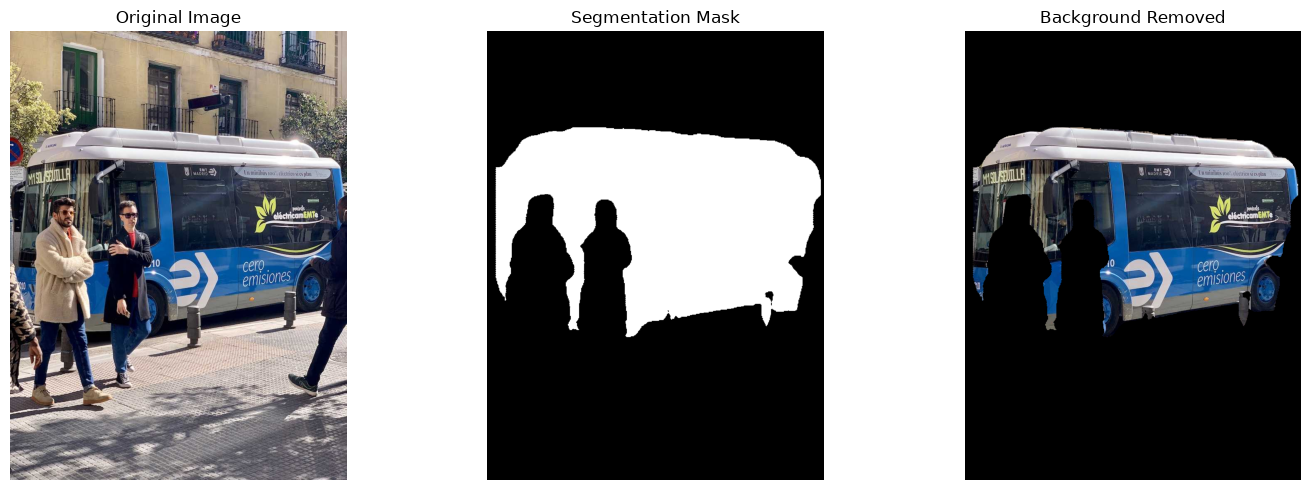

In [16]:
# Get the original image used for segmentation
original = cv2.imread("bus.jpg")
original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

# Extract the first object's mask
mask = masks[0]

# Resize mask to original image dimensions
mask = cv2.resize(
    mask,
    (original.shape[1], original.shape[0])
)

# Convert mask to binary
binary_mask = (mask > 0.5).astype("uint8")

# Keep object pixels and remove background
isolated_object = original * binary_mask[:, :, np.newaxis]

# Display results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(original)
axes[0].set_title("Original Image")

axes[1].imshow(binary_mask, cmap="gray")
axes[1].set_title("Segmentation Mask")

axes[2].imshow(isolated_object)
axes[2].set_title("Background Removed")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()